&nbsp;

&nbsp;

## Survey: up5p enhancer-derived lncRNA pairs

&nbsp;

### BackGround

- 

&nbsp;

In [1]:
import re
import os
import pathlib
import datetime
import subprocess
import polars as pl
from IPython.display import display
from IPython.display import Image
from pygenometracks.readGtf import ReadGtf

pl.Config.set_fmt_str_lengths(200)
os.environ["POLARS_MAX_THREADS"] = "16"

In [2]:
execute_date = datetime.datetime.now().strftime("%y%m%d")  # noqa: DTZ005
print(f"Execute Date: {execute_date}")

Execute Date: 261019


&nbsp;

&nbsp;

&nbsp;

&nbsp;

## Up5p Upsetplot Intersection Result

In [3]:
up5p_intersect_result = pl.read_csv(
    "../../../out/transcript_classification/upsetplot/up5p_transcript_upset_data_v261010.tsv",
    separator="\t",
    n_threads=16
).with_columns(
    # Split "ENST...-FCHS_..." into transcript_id and cre_id
    pl.col("id")
    .str.split_exact("-", 1)
    .struct.rename_fields(["transcript_id", "cre_id"])
    .alias("id_parts")
).unnest("id_parts")


display(up5p_intersect_result)

all pairs,derived from CLS3 project,Diff Analysis (ATAC-seq),Diff Analysis (HSF1),divergent,enhancer-derived,id,transcript_id,cre_id
bool,bool,bool,bool,bool,bool,str,str,str
true,true,false,false,false,false,"""ENST00000762829.1-FCHS_442950""","""ENST00000762829.1""","""FCHS_442950"""
true,false,false,false,false,true,"""ENST00000607794.2-FCHS_149384""","""ENST00000607794.2""","""FCHS_149384"""
true,true,false,false,false,false,"""ENST00000830147.1-FCHS_318953""","""ENST00000830147.1""","""FCHS_318953"""
true,true,false,false,false,false,"""ENST00000773409.1-FCHS_199701""","""ENST00000773409.1""","""FCHS_199701"""
true,true,false,false,false,false,"""ENST00000810898.1-FCHS_17158""","""ENST00000810898.1""","""FCHS_17158"""
…,…,…,…,…,…,…,…,…
true,true,false,false,false,false,"""ENST00000772900.1-FCHS_130885""","""ENST00000772900.1""","""FCHS_130885"""
true,false,false,false,false,true,"""ENST00000423178.6-FCHS_466850""","""ENST00000423178.6""","""FCHS_466850"""
true,true,false,false,false,false,"""ENST00000783516.1-FCHS_110693""","""ENST00000783516.1""","""FCHS_110693"""


&nbsp;

&nbsp;

&nbsp;

&nbsp;

## HSF1 regulation  + Diff-Analysis + enhancer-derived

- 最も注目できる up5p transcripts の組み合わせ

In [4]:
hsf1_e_derived_lncrna = up5p_intersect_result.filter(
    (pl.col("Diff Analysis (HSF1)") == True)
    & (pl.col("divergent") == False)
    & (pl.col("Diff Analysis (ATAC-seq)") == True)
    & (pl.col("enhancer-derived") == True)
    # & (pl.col("derived from CLS3 project") == True)
)

display(hsf1_e_derived_lncrna)

all pairs,derived from CLS3 project,Diff Analysis (ATAC-seq),Diff Analysis (HSF1),divergent,enhancer-derived,id,transcript_id,cre_id
bool,bool,bool,bool,bool,bool,str,str,str
true,false,true,true,false,true,"""ENST00000701945.1-FCHS_345096""","""ENST00000701945.1""","""FCHS_345096"""
true,true,true,true,false,true,"""ENST00000842153.1-FCHS_267410""","""ENST00000842153.1""","""FCHS_267410"""
true,false,true,true,false,true,"""ENST00000531938.1-FCHS_85348""","""ENST00000531938.1""","""FCHS_85348"""
true,true,true,true,false,true,"""ENST00000771247.1-FCHS_15797""","""ENST00000771247.1""","""FCHS_15797"""
true,false,true,true,false,true,"""ENST00000701945.1-FCHS_345095""","""ENST00000701945.1""","""FCHS_345095"""
…,…,…,…,…,…,…,…,…
true,true,true,true,false,true,"""ENST00000686199.2-FCHS_354474""","""ENST00000686199.2""","""FCHS_354474"""
true,true,true,true,false,true,"""ENST00000773816.1-FCHS_279918""","""ENST00000773816.1""","""FCHS_279918"""
true,true,true,true,false,true,"""ENST00000689737.3-FCHS_73669""","""ENST00000689737.3""","""FCHS_73669"""


&nbsp;

&nbsp;

## Transcript - CRE pairs

- 今回の解析で、具体的にどのような transcript - CRE pair が取得できたか確認する

In [5]:
up5p_cre_pair = pl.read_parquet(
    "../../../out/fantabio/parquet_file/up5p_transcript_fantabio_v261001.parquet"
).filter(
    # pair としてフィルタリング
    (pl.col("transcript_id").is_in(hsf1_e_derived_lncrna.get_column("transcript_id").unique().implode()))
    & (pl.col("cre_id").is_in(hsf1_e_derived_lncrna.get_column("cre_id").unique().implode()))
)

print(f"up5p cre all pair: {up5p_cre_pair.select(['transcript_id', 'cre_id']).n_unique()}")
pl.Config.set_tbl_rows(20)
display(up5p_cre_pair)

up5p cre all pair: 17


transcript_id,UP2,DOWN2,UNCHANGED2,HN2,UP2_stranded,DOWN2_stranded,UNCHANGED2_stranded,HN2_stranded,gene_symbol,HGNC_ID,transcript_type,gene_id,tags,strand,number_of_tags,RNACentral_ID,corrrespondence,polyA_features,gene_source,annotation_remarks,annotation_remark_count,cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,transcript_distance,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers,directionality,fantabio_cre_class,itemRgb,itemRgb_name
str,i64,i64,i64,i64,i64,i64,i64,i64,str,str,str,str,list[str],str,u32,str,str,list[str],str,list[str],u32,str,str,i64,str,str,list[str],str,i64,list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]],f64,str,str,str
"""ENST00000686199.2""",210,24,172,186,118,10,123,108,null,null,"""lncRNA""","""ENSG00000289637.2""","[""basic"", ""TAGENE""]","""-""",2,"""URS0002A2F8A7""","""ENSEMBL_GENCODE""",null,"""havana_tagene_homo_sapiens""","[""CLS3 project"", ""Assembled from PacBio CLS3 reads""]",2,"""FCHS_354474""","""chr6""",31821758,"""31822349""","""cp10@SNHG32""","[""ENST00000718216.1"", ""ENST00000718219.1"", … ""ENST00000718221.1""]","""0""",0,"[{""EH38E3700971"",""PLS""}, {""EH38E3700972"",""pELS""}]","[{""NFE2"",2671,[{""SRX2424107"",2671}, {""SRX2424108"",2272}, … {""SRX646135"",749}]}, {""HSF1"",2314,[{""SRX16646111"",2314}, {""SRX6858250"",1772}, … {""SRX262145"",577}]}, … {""STAT1"",507,[{""SRX212650"",507}]}]","[{""HS_00075267"",""Foreskin Fibroblast Primary Cells skin02"",""Prepuce"",""Skin"",""SVM""}, {""HS_00075268"",""H1 Cells"",""Embryonic stem cell"",""Stem cell"",""SVM""}]","[{""hg19::chr6:31789738..31789757,-;hg_72842.1"",""hg_72842.1""}, {""hg19::chr6:31789892..31789941,+;hg_67055.1"",""hg_67055.1""}, … {""hg19::chr6:31790120..31790128,+;hg_67059.1"",""hg_67059.1""}]","[{[""chr6:31821895-31822503""]}]",0.554413,"""PLA""","""101,0,0""","""dark_red"""
"""ENST00000792518.1""",168,14,224,154,89,5,157,84,null,null,"""lncRNA""","""ENSG00000289170.2""","[""TAGENE""]","""-""",1,"""URS0002A4A76A""","""ENSEMBL_GENCODE""",null,"""havana_tagene_homo_sapiens""","[""CLS3 project""]",1,"""FCHS_345095""","""chr5""",172772223,"""172772840""","""cp6@LOC105377730""","[""ENST00000792661.1""]","""0""",0,"[{""EH38E2432320"",""pELS""}, {""EH38E3678979"",""PLS""}, {""EH38E3678980"",""PLS""}]","[{""HSF1"",3715,[{""SRX16646111"",3715}, {""SRX16646095"",2649}, … {""SRX13845496"",511}]}, {""CTCF"",2892,[{""SRX10976008"",2892}, {""SRX10976002"",2661}, … {""SRX12008354"",982}]}, … {""TFE3"",503,[{""SRX15431002"",503}]}]","[{""HS_00070503"",""H1 Cells"",""Embryonic stem cell"",""Stem cell"",""SVM""}, {""HS_00070504"",""H1 Derived Neuronal Progenitor Cultured Cells"",""Brain"",""Brain"",""SVM""}, … {""HS_00070506"",""H1 BMP4 Derived Mesendoderm Cultured Cells"",""Mesendoderm cell"",""Others"",""SVM""}]","[{""hg19::chr5:172199220..172199230,-;hg_64898.1"",""hg_64898.1""}, {""hg19::chr5:172199270..172199285,-;hg_64899.1"",""hg_64899.1""}, … {""hg38::chr5:172772240..172772247,+;hg_229768.1"",""hg_229768.1""}]","[{[""chr5:172771532-172772956""]}]",0.145975,"""PLA""","""0,0,0""","""black"""
"""ENST00000792518.1""",168,14,224,154,89,5,157,84,null,null,"""lncRNA""","""ENSG00000289170.2""","[""TAGENE""]","""-""",1,"""URS0002A4A76A""","""ENSEMBL_GENCODE""",null,"""havana_tagene_homo_sapiens""","[""CLS3 project""]",1,"""FCHS_345096""","""chr5""",172772607,"""172773187""","""FCHS_345096""","[""ENST00000792518.1""]","""0""",0,"[{""EH38E2432320"",""pELS""}, {""EH38E3678980"",""PLS""}, {""EH38E3678981"",""pELS""}]","[{""HSF1"",3715,[{""SRX16646111"",3715}, {""SRX16646095"",2649}, … {""SRX3322007"",532}]}, {""GATA1"",2571,[{""SRX5931550"",2571}, {""SRX5821030"",2052}, … {""SRX8536111"",524}]}, … {""GATA2"",500,[{""SRX100585"",500}]}]","[{""HS_00070503"",""H1 Cells"",""Embryonic stem cell"",""Stem cell"",""SVM""}, {""HS_00070504"",""H1 Derived Neuronal Progenitor Cultured Cells"",""Brain"",""Brain"",""SVM

&nbsp;

&nbsp;

&nbsp;

&nbsp;

## 2. ENCODE-rE2G result

- 複数ある transcript - CRE pair の中から、ENCODE-rE2G の結果を活用し、活性化していると思われるCRE とそのペアを選抜する

In [6]:
enemal_encode_re2g_result = pl.read_parquet(
    "../../../out/ENCODE_rE2G/parquet_file/encode_re2g_hs_join_v261003.parquet"
).filter(
    pl.col("isSelfPromoter") == False
).filter(
    # 選抜した CRE のみを対象にする
    pl.col("cre_id").is_in(
        up5p_cre_pair.get_column("cre_id").unique().implode()
    )
)

enemal_e2g_join_filter_unique_count = enemal_encode_re2g_result.group_by(
    "cre_id",
    "cre_name",
    "fantabio_cre_class",
    "target_cre_id",
    "target_cre_name",
    "target_fantabio_cre_class"
).agg(
    # Keep dataset order so this list lines up with the score and overlap lists
    pl.col("re2g_dataset").unique(maintain_order=True).alias("re2g_dataset"),
    pl.col("re2g_dataset").n_unique().alias("re2g_dataset_count"),
    pl.col("enhancer_cre_overlap_frac_of_fantabio_cre").alias("enhancer_cre_overlap_frac_of_fantabio_cre"),
    pl.col("enhancer_cre_overlap_frac_of_fantabio_cre").min().alias("enhancer_cre_overlap_frac_of_fantabio_cre_min"),
    pl.col("enhancer_cre_overlap_frac_of_fantabio_cre").max().alias("enhancer_cre_overlap_frac_of_fantabio_cre_max"),
    pl.col("enhancer_cre_overlap_frac_of_fantabio_cre").mean().alias("enhancer_cre_overlap_frac_of_fantabio_cre_mean"), # 該当するデータセットで同定された enhancer と fantabio の CRE の重複率の平均値

    pl.col("ENCODE-rE2G.Score").alias("ENCODE-rE2G.Score"),
    pl.col("ENCODE-rE2G.Score").min().alias("ENCODE-rE2G.Score_min"),
    pl.col("ENCODE-rE2G.Score").max().alias("ENCODE-rE2G.Score_max"),
    pl.col("ENCODE-rE2G.Score").mean().alias("ENCODE-rE2G.Score_mean"), # 該当するデータセットで同定された enhancer と target promoter の相互作用のスコアの平均値

    # pl.col("ENCODE-rE2G.Score").quantile(0.25).alias("ENCODE-rE2G.Score_q1"),
    # pl.col("ENCODE-rE2G.Score").median().alias("ENCODE-rE2G.Score_median"),
    # pl.col("ENCODE-rE2G.Score").quantile(0.75).alias("ENCODE-rE2G.Score_q3"),
    # pl.col("ENCODE-rE2G.Score").std().alias("ENCODE-rE2G.Score_std"),
).sort(
    by=["re2g_dataset_count"],
    descending=True
).filter(
    pl.col("re2g_dataset_count") >= 12 # 10 以上のデータセットで同定された CRE との相互作用を対象にする
)

pl.Config.set_tbl_rows(30)
print(f"ENCODE-rE2G enhancer - target region interaction unique pair count (fanta.bio cre level): {enemal_e2g_join_filter_unique_count.select(['cre_id', 'target_cre_id']).n_unique()}")
display(enemal_e2g_join_filter_unique_count)

ENCODE-rE2G enhancer - target region interaction unique pair count (fanta.bio cre level): 11


cre_id,cre_name,fantabio_cre_class,target_cre_id,target_cre_name,target_fantabio_cre_class,re2g_dataset,re2g_dataset_count,enhancer_cre_overlap_frac_of_fantabio_cre,enhancer_cre_overlap_frac_of_fantabio_cre_min,enhancer_cre_overlap_frac_of_fantabio_cre_max,enhancer_cre_overlap_frac_of_fantabio_cre_mean,ENCODE-rE2G.Score,ENCODE-rE2G.Score_min,ENCODE-rE2G.Score_max,ENCODE-rE2G.Score_mean
str,str,str,str,str,str,list[str],u32,list[f64],f64,f64,f64,list[f64],f64,f64,f64
"""FCHS_73669""","""cp2@LINC02736""","""PLA""","""FCHS_73694""","""cp7@MALAT1""","""PLA""","[""GSE101731_HFF_44C_120min"", ""GSE101731_HFF_44C_60min"", … ""GSE280307_THP1_42C_120min""]",14,"[0.611247, 0.611247, … 0.811736]",0.611247,1.0,0.696385,"[0.709414, 0.546621, … 0.736767]",0.374908,0.781765,0.594557
"""FCHS_94451""","""FCHS_94451""","""PLA""","""FCHS_94499""","""cp1@ATG101""","""PLA""","[""GSE101731_HFF_44C_120min"", ""GSE101731_HFF_44C_60min"", … ""GSE280307_THP1_42C_120min""]",14,"[0.778816, 0.778816, … 0.904984]",0.767913,0.904984,0.806297,"[0.355003, 0.189876, … 0.526484]",0.189876,0.774307,0.408416
"""FCHS_94451""","""FCHS_94451""","""PLA""","""FCHS_94475""","""cp11@NR4A1""","""PLA""","[""GSE101731_HFF_44C_120min"", ""GSE101731_HFF_44C_60min"", … ""GSE280307_THP1_42C_120min""]",14,"[0.778816, 0.778816, … 0.904984]",0.767913,0.904984,0.806297,"[0.507285, 0.330384, … 0.71298]",0.330384,0.865387,0.691837
"""FCHS_15797""","""FCHS_15797""","""ELA""","""FCHS_15789""","""cp4@FOXD3""","""ELA""","[""GSE101731_HFF_44C_120min"", ""GSE101731_HFF_44C_60min"", … ""GSE280307_THP1_42C_120min""]",14,"[1.0, 1.0, … 1.0]",1.0,1.0,1.0,"[0.869593, 0.83766, … 0.848651]",0.5227,0.967003,0.846554
"""FCHS_354474""","""cp10@SNHG32""","""PLA""","""FCHS_354464""","""cp2@HSPA1A,cp2@HSPA1L""","""PLA""","[""GSE101731_HFF_44C_60min"", ""GSE105028_hESC_42C_60min"", … ""GSE280307_THP1_42C_120min""]",13,"[0.608108, 1.0, … 1.0]",0.523649,1.0,0.870322,"[0.217618, 0.97078, … 0.776343]",0.217618,0.97078,0.788662
"""FCHS_107551""","""FCHS_107551""","""PLA""","""FCHS_107477""","""cp8@SCARB1""","""PLA""","[""GSE101731_HFF_44C_120min"", ""GSE101731_HFF_44C_60min"", … ""GSE280307_THP1_42C_120min""]",13,"[0.883598, 1.0, … 1.0]",0.883598,1.0,0.975376,"[0.841868, 0.857204, … 0.488237]",0.219103,0.857204,0.508386
"""FCHS_73669""","""cp2@LINC02736""","""PLA""","""FCHS_73545""","""cp2@NEAT1""","""PLA""","[""GSE101731_HFF_44C_120min"", ""GSE101731_HFF_44C_60min"", … ""GSE280307_THP1_42C_120min""]",13,"[0.611247, 0.611247, … 0.811736]",0.611247,1.0,0.702934,"[0.309918, 0.205503, … 0.357179]",0.205503,0.538275,0.351038
"""FCHS_279918""","""FCHS_279918""","""PLA""","""FCHS_279932""","""cp1@HDAC11,cp1@HDAC11-AS1""","""PLA""","[""GSE101731_HFF_44C_120min"", ""GSE101731_HFF_44C_60min"", … ""GSE280307_THP1_42C_120min""]",13,"[1.0, 1.0, … 1.0]",0.752244,1.0,0.965336,"[0.64231, 0.222779, … 0.737152]",0.222779,0.87494,0.512844
"""FCHS_15797""","""FCHS_15797""","""ELA""","""FCHS_15773""","""cp3@LINC00466""","""PLA""","[""GSE101731_HFF_44C_120min"", ""GSE101731_HFF_44C_60min"", … ""GSE280307_THP1_42C_120min""]",13,"[1.0, 1.0, … 1.0]",1.0,1.0,1.0,"[0.247319, 0.229369, … 0.311737]",0.179663,0.66386,0.343593


&nbsp;

&nbsp;

&nbsp;

&nbsp;

## 3. Representative CRE -> FCHS_94451 (ENST00000812391.1 - FCHS_94451)

- この notebook では、FCHS_94451 に焦点を当てる

In [7]:
FCHS_94451_e2g_target = enemal_e2g_join_filter_unique_count.filter(
    pl.col("cre_id") == "FCHS_94451"
)

FCHS_94451_transcript_pair = up5p_cre_pair.filter(
    pl.col("cre_id") == "FCHS_94451"
)

display(FCHS_94451_e2g_target)
display(FCHS_94451_transcript_pair)

cre_id,cre_name,fantabio_cre_class,target_cre_id,target_cre_name,target_fantabio_cre_class,re2g_dataset,re2g_dataset_count,enhancer_cre_overlap_frac_of_fantabio_cre,enhancer_cre_overlap_frac_of_fantabio_cre_min,enhancer_cre_overlap_frac_of_fantabio_cre_max,enhancer_cre_overlap_frac_of_fantabio_cre_mean,ENCODE-rE2G.Score,ENCODE-rE2G.Score_min,ENCODE-rE2G.Score_max,ENCODE-rE2G.Score_mean
str,str,str,str,str,str,list[str],u32,list[f64],f64,f64,f64,list[f64],f64,f64,f64
"""FCHS_94451""","""FCHS_94451""","""PLA""","""FCHS_94499""","""cp1@ATG101""","""PLA""","[""GSE101731_HFF_44C_120min"", ""GSE101731_HFF_44C_60min"", … ""GSE280307_THP1_42C_120min""]",14,"[0.778816, 0.778816, … 0.904984]",0.767913,0.904984,0.806297,"[0.355003, 0.189876, … 0.526484]",0.189876,0.774307,0.408416
"""FCHS_94451""","""FCHS_94451""","""PLA""","""FCHS_94475""","""cp11@NR4A1""","""PLA""","[""GSE101731_HFF_44C_120min"", ""GSE101731_HFF_44C_60min"", … ""GSE280307_THP1_42C_120min""]",14,"[0.778816, 0.778816, … 0.904984]",0.767913,0.904984,0.806297,"[0.507285, 0.330384, … 0.71298]",0.330384,0.865387,0.691837


transcript_id,UP2,DOWN2,UNCHANGED2,HN2,UP2_stranded,DOWN2_stranded,UNCHANGED2_stranded,HN2_stranded,gene_symbol,HGNC_ID,transcript_type,gene_id,tags,strand,number_of_tags,RNACentral_ID,corrrespondence,polyA_features,gene_source,annotation_remarks,annotation_remark_count,cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,transcript_distance,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers,directionality,fantabio_cre_class,itemRgb,itemRgb_name
str,i64,i64,i64,i64,i64,i64,i64,i64,str,str,str,str,list[str],str,u32,str,str,list[str],str,list[str],u32,str,str,i64,str,str,list[str],str,i64,list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]],f64,str,str,str
"""ENST00000812391.1""",144,16,246,128,71,7,173,64,null,null,"""lncRNA""","""ENSG00000305684.1""","[""basic"", ""Ensembl_canonical"", … ""TAGENE""]","""-""",4,"""URS0002A236EE""","""ENSEMBL_GENCODE""",null,"""havana_tagene_homo_sapiens""","[""CLS3 project""]",1,"""FCHS_94451""","""chr12""",52032765,"""52033406""","""FCHS_94451""","[""ENST00000812391.1""]","""0""",0,"[{""EH38E1612154"",""dELS""}]","[{""FLI1"",3270,[{""SRX117010"",3270}, {""SRX117011"",3229}, … {""SRX10144613"",606}]}, {""ASCL1"",3020,[{""SRX8949797"",3020}, {""SRX11245139"",2649}, … {""SRX17737100"",654}]}, … {""RXRA"",501,[{""SRX5457234"",501}]}]","[{""HS_00172322"",""H1 Cells"",""Embryonic stem cell"",""Stem cell"",""SVM""}, {""HS_00172323"",""Breast variant Human Mammary Epithelial Cells (vHMEC)"",""Breast"",""Breast"",""SVM""}, … {""HS_00172329"",""H1 BMP4 Derived Mesendoderm Cultured Cells"",""Mesendoderm cell"",""Others"",""SVM""}]","[{""hg19::chr12:52426680..52426686,-;hg_130979.1"",""hg_130979.1""}, {""hg19::chr12:52426731..52426752,-;hg_130980.1"",""hg_130980.1""}, … {""hg19::chr12:52427143..52427164,+;hg_125551.1"",""hg_125551.1""}]","[{[""chr12:52032715-52033380""]}]",-0.114194,"""PLA""","""0,0,0""","""black"""


&nbsp;

&nbsp;

&nbsp;

&nbsp;

## 5. Target cre proximal transcript check

- この、FCHS_94451 に制御されている可能性のある target cre id の近傍の transcript が、今回の研究で、up5p transcript に分類されているか check!

In [8]:
target_cre_proximal_transcript = pl.read_parquet(
    "../../../out/fantabio/parquet_file/up5p_transcript_fantabio_v261001.parquet"
).filter(
    # ENEMAL に制御されている可能性のある target cre id の近傍の transcript を対象にする
    pl.col("cre_id").is_in(
        FCHS_94451_e2g_target.get_column("target_cre_id").unique().implode()
    )
)

pl.Config.set_tbl_rows(20)
print(f"Target CRE Unique List: {target_cre_proximal_transcript.select('cre_id').unique()}")
print(f"Target CRE-related Transcript Unique List: {target_cre_proximal_transcript.select('transcript_id').unique()}")

pl.Config.set_tbl_rows(2)
display(target_cre_proximal_transcript)

Target CRE Unique List: shape: (2, 1)
┌────────────┐
│ cre_id     │
│ ---        │
│ str        │
╞════════════╡
│ FCHS_94475 │
│ FCHS_94499 │
└────────────┘
Target CRE-related Transcript Unique List: shape: (17, 1)
┌───────────────────┐
│ transcript_id     │
│ ---               │
│ str               │
╞═══════════════════╡
│ ENST00000908678.1 │
│ ENST00000547409.1 │
│ ENST00000243050.5 │
│ ENST00000908677.1 │
│ ENST00000548232.2 │
│ ENST00000394825.6 │
│ ENST00000948107.1 │
│ ENST00000548915.1 │
│ ENST00000548733.1 │
│ ENST00000875313.1 │
│ ENST00000552544.5 │
│ ENST00000850963.1 │
│ ENST00000552947.1 │
│ ENST00000875319.1 │
│ ENST00000875320.1 │
│ ENST00000820082.1 │
│ ENST00000550763.1 │
└───────────────────┘


transcript_id,UP2,DOWN2,UNCHANGED2,HN2,UP2_stranded,DOWN2_stranded,UNCHANGED2_stranded,HN2_stranded,gene_symbol,HGNC_ID,transcript_type,gene_id,tags,strand,number_of_tags,RNACentral_ID,corrrespondence,polyA_features,gene_source,annotation_remarks,annotation_remark_count,cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,transcript_distance,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers,directionality,fantabio_cre_class,itemRgb,itemRgb_name
str,i64,i64,i64,i64,i64,i64,i64,i64,str,str,str,str,list[str],str,u32,str,str,list[str],str,list[str],u32,str,str,i64,str,str,list[str],str,i64,list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]],f64,str,str,str
"""ENST00000948107.1""",233,19,154,214,135,15,101,120,"""NR4A1""","""HGNC:7980""","""protein_coding""","""ENSG00000123358.21""","[""basic"", ""TAGENE"", … ""CCDS""]","""+""",4,null,null,null,"""ensembl_havana_gene_homo_sapiens""","[""ENCODE_tissue""]",1,"""FCHS_94475""","""chr12""",52050988,"""52051641""","""cp11@NR4A1""","[""ENST00000243050.5"", ""ENST00000875320.1"", … ""D49728""]","""0""",0,"[{""EH38E1612186"",""pELS""}, {""EH38E3017342"",""PLS""}, {""EH38E3017343"",""PLS""}]","[{""CTCF"",3937,[{""SRX10975999"",3937}, {""SRX10976007"",3668}, … {""SRX9867032"",502}]}, {""SRF"",2734,[{""SRX5457185"",2734}, {""SRX5457184"",2477}, … {""SRX702113"",564}]}, … {""ZHX2"",500,[{""SRX3636887"",500}]}]","[{""HS_00172332"",""H1 BMP4 Derived Mesendoderm Cultured Cells"",""Mesendoderm cell"",""Others"",""SVM""}, {""HS_00172333"",""Fetal Brain Female"",""Brain"",""Brain"",""SVM""}]","[{""hg19::chr12:52444766..52444777,-;hg_130985.1"",""hg_130985.1""}, {""hg19::chr12:52444895..52444916,-;hg_130986.1"",""hg_130986.1""}, … {""hg19::chr12:52445218..52445237,+;hg_125560.1"",""p1@NR4A1""}]",null,0.947158,"""PLA""","""204,0,0""","""red"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""ENST00000548915.1""",93,47,266,46,54,31,166,23,"""ATG101""","""HGNC:25679""","""protein_coding""","""ENSG00000123395.16""","[""cds_end_NF"", ""mRNA_end_NF"", ""alternative_5_UTR""]","""+""",3,null,null,null,"""ensembl_havana_gene_homo_sapiens""","[""alternative 5' UTR""]",1,"""FCHS_94499""","""chr12""",52069496,"""52070201""","""cp1@ATG101""","[""ENST00000938048.1"", ""ENST00000908677.1"", … ""BC009937""]","""0""",0,"[{""EH38E1612230"",""pELS""}, {""EH38E3017386"",""PLS""}, {""EH38E3017387"",""PLS""}]","[{""ASXL2"",4031,[{""SRX14203243"",4031}]}, {""ATF7"",3586,[{""SRX3322915"",3586}, {""SRX3322914"",3508}, … {""SRX3323023"",1099}]}, … {""SOX10"",501,[{""SRX21457791"",501}]}]","[{""HS_00172335"",""HMEC Mammary Epithelial Primary Cells"",""Mammary gland"",""Breast"",""SVM""}, {""HS_00172336"",""Fetal Intestine Small"",""Small intestine"",""Intestine"",""SVM""}, … {""HS_00172339"",""H1 Cells"",""Embryonic stem cell"",""Stem cell"",""SVM""}]","[{""hg19::chr12:52463751..52463814,+;hg_125573.1"",""p1@ATG101""}, {""hg19::chr12:52463884..52463905,+;hg_125574.1"",""p2@ATG101""}]",null,0.995932,"""PLA""","""204,0,0""","""red"""


&nbsp;

&nbsp;

&nbsp;

## Visualization

### 表示領域

- UCSC Genome Browser で決めた窓をそのまま使う
- [UCSC Genome Browser Result](https://genome.ucsc.edu/cgi-bin/hgTracks?db=hg38&lastVirtModeType=default&lastVirtModeExtraState=&virtModeType=default&virtMode=0&nonVirtPosition=&position=chr12%3A52026707%2D52096042&hgsid=4210691301_mYzEJhg95Ri1xwr1sfjbDKjCFE4Y)
- Region: chr12:52,026,707-52,096,042（約 69 kb）
- FCHS_94451、その target CRE（FCHS_94475, FCHS_94499）、対象 transcript はすべて chr12 のこの窓の中にある

### Related Dataframe

1. `FCHS_94451_transcript_pair`（注目する transcript。`ENST00000812391.1`、gene symbol は未付与なので `ENSG00000306678.1`）
2. `FCHS_94451_e2g_target`（FCHS_94451 から target CRE への ENCODE-rE2G）
3. `target_cre_proximal_transcript`（target CRE 近傍の up5p transcript。NR4A1 と ATG101）

In [9]:
# Plot window chosen on the UCSC Genome Browser (hg38).
# https://genome.ucsc.edu/cgi-bin/hgTracks?db=hg38&position=chr12%3A52026707-52096042

REGION_CHROM = "chr12"
REGION_START = 52_026_707
REGION_END = 52_096_042

repo_root = pathlib.Path("../../../").resolve()
gtf_full = repo_root / "Data/Database/GENCODE_v49/gencode.v49.chr_patch_hapl_scaff.annotation.gtf"
cre_full = repo_root / "Data/Database/fantabio/human-CREv1.2.1.hg38.cre-peaks.bed"
out_dir = (
    repo_root
    / "out/transcript_survey/pygenometracks"
    / f"ENST00000812391_FCHS_94451_{REGION_CHROM}_{REGION_START}_{REGION_END}"
)
out_dir.mkdir(parents=True, exist_ok=True)

print(out_dir)

/workspaces/HS_human_ncRNA/out/transcript_survey/pygenometracks/ENST00000812391_FCHS_94451_chr12_52026707_52096042


In [10]:
# Enhancer-promoter arcs (one arc per CRE pair).
ep_pairs = FCHS_94451_e2g_target.select(
    "cre_id", "target_cre_id", "target_cre_name", "ENCODE-rE2G.Score_mean", "re2g_dataset_count"
).unique(subset=["cre_id", "target_cre_id"], maintain_order=True)

cre_ids = pl.concat(
    [
        ep_pairs.select("cre_id"),
        ep_pairs.select(pl.col("target_cre_id").alias("cre_id")),
    ]
).unique(maintain_order=True)

# fanta.bio BED has 11 columns; pyGenomeTracks reads itemRgb only up to BED9.
# Column 4 is replaced by cre_name (e.g. cp11@NR4A1) so the label shows the gene.
cre_keep = pl.read_csv(
    cre_full,
    separator="\t",
    has_header=False,
    new_columns=[
        "chrom", "start", "end", "cre_id", "score", "strand",
        "thick_start", "thick_end", "item_rgb", "cre_name", "annot",
    ],
).join(cre_ids, on="cre_id", how="inner")

cre_bed9 = out_dir / "FCHS_94451_cre.bed9.bed"
cre_keep.select(
    "chrom", "start", "end", "cre_name", "score", "strand",
    "thick_start", "thick_end", "item_rgb",
).write_csv(cre_bed9, separator="\t", include_header=False)

coords = cre_keep.select("cre_id", "chrom", "start", "end")
links = (
    ep_pairs.join(
        coords.rename({"chrom": "chrom1", "start": "start1", "end": "end1"}),
        on="cre_id",
        how="inner",
    ).join(
        coords.rename(
            {
                "cre_id": "target_cre_id",
                "chrom": "chrom2",
                "start": "start2",
                "end": "end2",
            }
        ),
        on="target_cre_id",
        how="inner",
    )
).select(
    "chrom1", "start1", "end1", "chrom2", "start2", "end2",
    pl.col("ENCODE-rE2G.Score_mean"),
)
re2g_links = out_dir / "FCHS_94451_re2g.links"
links.write_csv(re2g_links, separator="\t", include_header=False)

print(f"CRE intervals: {cre_keep.height}")
print(f"arcs: {links.height}")
display(ep_pairs)
display(links)

CRE intervals: 3
arcs: 2


cre_id,target_cre_id,target_cre_name,ENCODE-rE2G.Score_mean,re2g_dataset_count
str,str,str,f64,u32
"""FCHS_94451""","""FCHS_94499""","""cp1@ATG101""",0.408416,14
"""FCHS_94451""","""FCHS_94475""","""cp11@NR4A1""",0.691837,14


chrom1,start1,end1,chrom2,start2,end2,ENCODE-rE2G.Score_mean
str,i64,i64,str,i64,i64,f64
"""chr12""",52032764,52033406,"""chr12""",52050987,52051641,0.691837
"""chr12""",52032764,52033406,"""chr12""",52069495,52070201,0.408416


In [11]:
# Full transcript models for the focal lncRNA and the up5p transcripts near the target CREs.
# A gtf track has one color, so convert to BED12 and color only by strand.
# This lncRNA has no gene symbol, so fall back to the Ensembl gene id.
gene_label = (
    pl.when(pl.col("gene_symbol").is_not_null())
    .then(pl.col("gene_symbol"))
    .otherwise(pl.col("gene_id"))
)
tx_info = pl.concat(
    [
        FCHS_94451_transcript_pair.select(
            "transcript_id",
            gene_label.alias("group"),
        ),
        target_cre_proximal_transcript.select(
            "transcript_id",
            gene_label.alias("group"),
        ),
    ]
).unique(subset="transcript_id", maintain_order=True)

# Plus strand in blue, minus strand in orange.
STRAND_RGB = {
    "+": "0,114,178",
    "-": "230,120,0",
}
tx_group = dict(zip(tx_info["transcript_id"], tx_info["group"]))
focal_tx = set(FCHS_94451_transcript_pair.get_column("transcript_id").unique())

# BED12 blocks must span the whole transcript, so pull full models from the GTF.
gtf_header = subprocess.run(
    ["grep", "^#", str(gtf_full)],
    check=True,
    capture_output=True,
    text=True,
)
tx_gtf_full = out_dir / "ENST00000812391_FCHS_94451_transcripts.full.gtf"
tx_patterns = "".join(f'transcript_id "{tx_id}";\n' for tx_id in sorted(tx_group))
tx_full_hits = subprocess.run(
    ["grep", "-F", "-f", "-", str(gtf_full)],
    input=tx_patterns,
    check=True,
    capture_output=True,
    text=True,
)
tx_gtf_full.write_text(gtf_header.stdout + tx_full_hits.stdout)

tx_bed12 = out_dir / "ENST00000812391_FCHS_94451_transcripts.bed12.bed"
tx_found = set()
with tx_bed12.open("w") as handle_out:
    for tx in ReadGtf(str(tx_gtf_full), prefered_name="transcript_id", merge_transcripts=False):
        group = tx_group[tx.name]
        tx_found.add(tx.name)
        # Focal lncRNA is labeled by transcript id only, same as the ENEMAL figure.
        if tx.name in focal_tx or group == tx.name:
            label = tx.name
        else:
            label = f"{tx.name} ({group})"
        handle_out.write(
            "\t".join(
                map(
                    str,
                    [
                        tx.chromosome, tx.start, tx.end, label, tx.score, tx.strand,
                        tx.thick_start, tx.thick_end, STRAND_RGB[tx.strand], tx.block_count,
                        ",".join(map(str, tx.block_sizes)),
                        ",".join(map(str, tx.block_starts)),
                    ],
                )
            )
            + "\n"
        )

print(f"transcripts in dataframe: {len(tx_group)}, written to BED12: {len(tx_found)}")
display(tx_info)

transcripts in dataframe: 18, written to BED12: 18


transcript_id,group
str,str
"""ENST00000812391.1""","""ENSG00000305684.1"""
…,…
"""ENST00000548915.1""","""ATG101"""


INFO:pygenometracks.tracksClass:initialize 1. [spacer]
INFO:pygenometracks.tracksClass:initialize 2. [x-axis]
INFO:pygenometracks.tracksClass:initialize 3. [spacer]
INFO:pygenometracks.tracksClass:initialize 4. [rE2G arcs]
100%|██████████| 2/2 [00:00<00:00, 30504.03it/s]
INFO:pygenometracks.tracksClass:initialize 5. [spacer]
INFO:pygenometracks.tracksClass:initialize 6. [fanta CRE]
100%|██████████| 3/3 [00:00<00:00, 37117.73it/s]
INFO:pygenometracks.tracksClass:initialize 7. [spacer]
INFO:pygenometracks.tracksClass:initialize 8. [transcripts]
100%|██████████| 18/18 [00:00<00:00, 85404.38it/s]
INFO:pygenometracks.tracksClass:time initializing track(s):
INFO:pygenometracks.tracksClass:0.0066127777099609375
DEBUG:pygenometracks.tracksClass:Figure size in cm is 30.0 x 24.20212765957447. Dpi is set to 150

INFO:pygenometracks.tracksClass:plotting 1. [spacer]
INFO:pygenometracks.tracksClass:plotting 2. [x-axis]
INFO:pygenometracks.tracksClass:plotting 3. [spacer]
INFO:pygenometracks.tracksCl

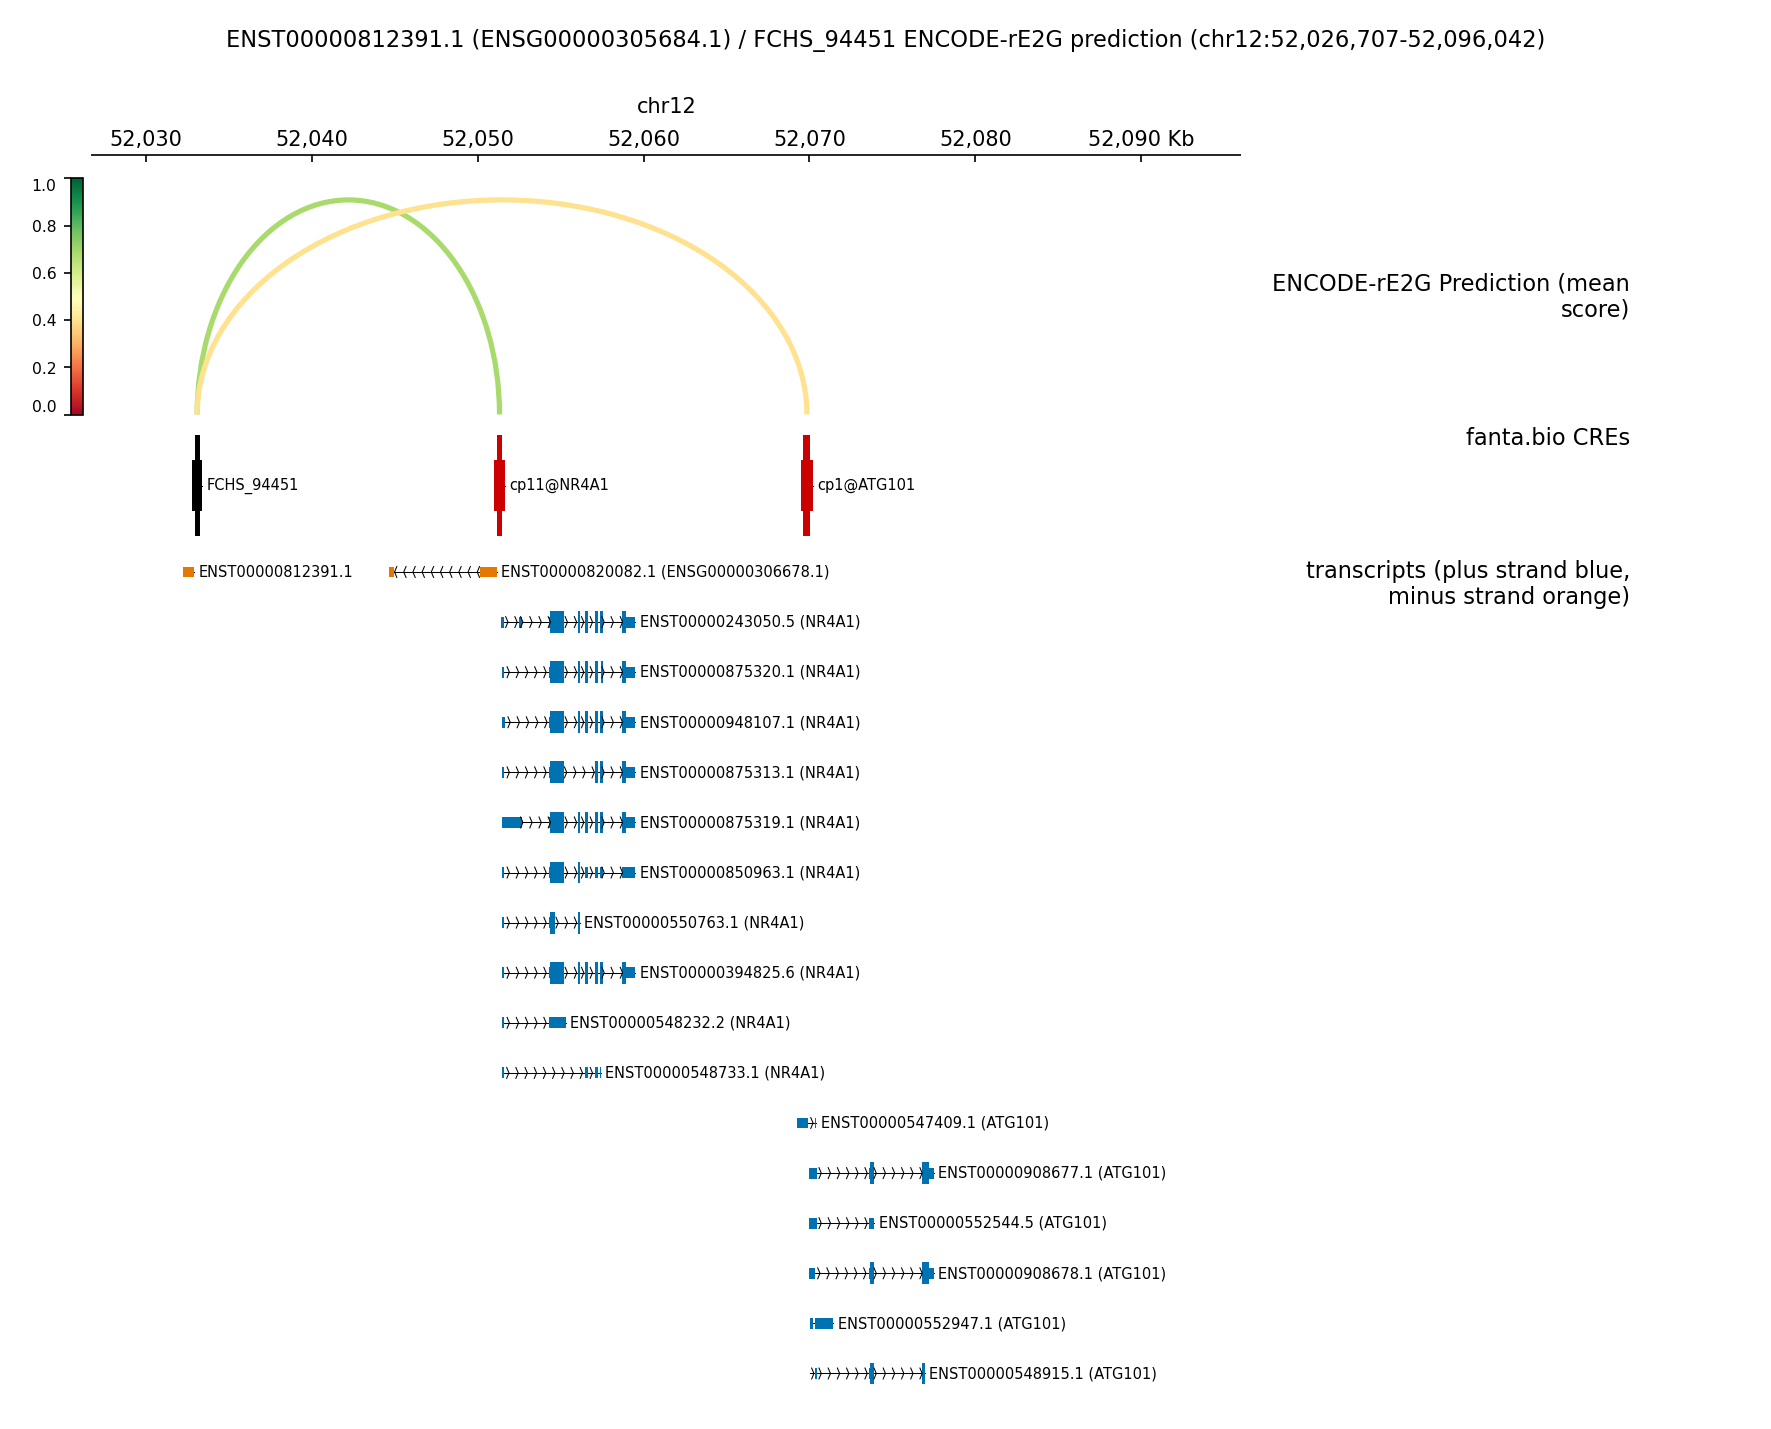

In [12]:
# Arcs on top, CRE anchors in the middle, transcript models at the bottom.
tracks_ini = out_dir / "ENST00000812391_FCHS_94451_tracks.ini"
figure_png = out_dir / "ENST00000812391_FCHS_94451_re2g.png"
focal_tx_id, focal_gene = (
    FCHS_94451_transcript_pair.select(
        "transcript_id",
        pl.when(pl.col("gene_symbol").is_not_null())
        .then(pl.col("gene_symbol"))
        .otherwise(pl.col("gene_id"))
        .alias("gene_label"),
    )
    .unique()
    .row(0)
)
figure_title = (
    f"{focal_tx_id} ({focal_gene}) / FCHS_94451 ENCODE-rE2G prediction "
    f"({REGION_CHROM}:{REGION_START:,}-{REGION_END:,})"
)
tracks_ini.write_text(
    f"""\
[spacer]
height = 0.9

[x-axis]
where = top
fontsize = 10

[spacer]
height = 0.15

[rE2G arcs]
file = {re2g_links.name}
title = ENCODE-rE2G Prediction (mean score)
file_type = links
links_type = arcs
use_middle = true
height = 4
color = RdYlGn
min_value = 0
max_value = 1
line_width = 2.5
line_style = solid
compact_arcs_level = 2

[spacer]
height = 0.2

[fanta CRE]
file = {cre_bed9.name}
title = fanta.bio CREs
file_type = bed
height = 2.0
color = bed_rgb
border_color = none
labels = true
fontsize = 7
style = UCSC
display = stacked

[spacer]
height = 0.25

[transcripts]
file = {tx_bed12.name}
title = transcripts (plus strand blue, minus strand orange)
file_type = bed
height = 14
color = bed_rgb
labels = true
all_labels_inside = true
fontsize = 7
style = UCSC
display = stacked
"""
)

# Mathtext draws digits with mathtext.rm, so both rm and it must be italic
# for gene symbols in the title to render fully italic.
mplrc = out_dir / "matplotlibrc"
mplrc.write_text(
    "mathtext.fontset : custom\n"
    "mathtext.rm : DejaVu Sans:italic\n"
    "mathtext.it : DejaVu Sans:italic\n"
)

subprocess.run(
    [
        "pyGenomeTracks",
        "--tracks",
        str(tracks_ini),
        "--region",
        f"{REGION_CHROM}:{REGION_START}-{REGION_END}",
        "--width",
        "30",
        "--dpi",
        "150",
        "--trackLabelFraction",
        "0.25",
        "--trackLabelHAlign",
        "right",
        "--outFileName",
        str(figure_png),
        "--title",
        figure_title,
    ],
    check=True,
    cwd=out_dir,
    env={**os.environ, "MATPLOTLIBRC": str(mplrc)},
)
display(Image(filename=str(figure_png)))
